# Preliminary analysis of trends

In [8]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")   # kpss/adfuller spam InterpolationWarnings
plt.rcParams["figure.figsize"] = (11, 4)

In [9]:
df = pd.read_csv("prices.txt", sep=r"\s+", header=0)
tickers = df.columns.to_numpy()
prc = df.values.T                       # (nInst, nt) — eval's orientation, ALGO = row 0
nInst, nt = prc.shape
rets = np.diff(np.log(prc), axis=1)     # rets[:, t] = close t → close t+1

ret_df = pd.DataFrame(rets.T, columns=tickers)   # days-as-rows view, nicer for plotting/.rolling

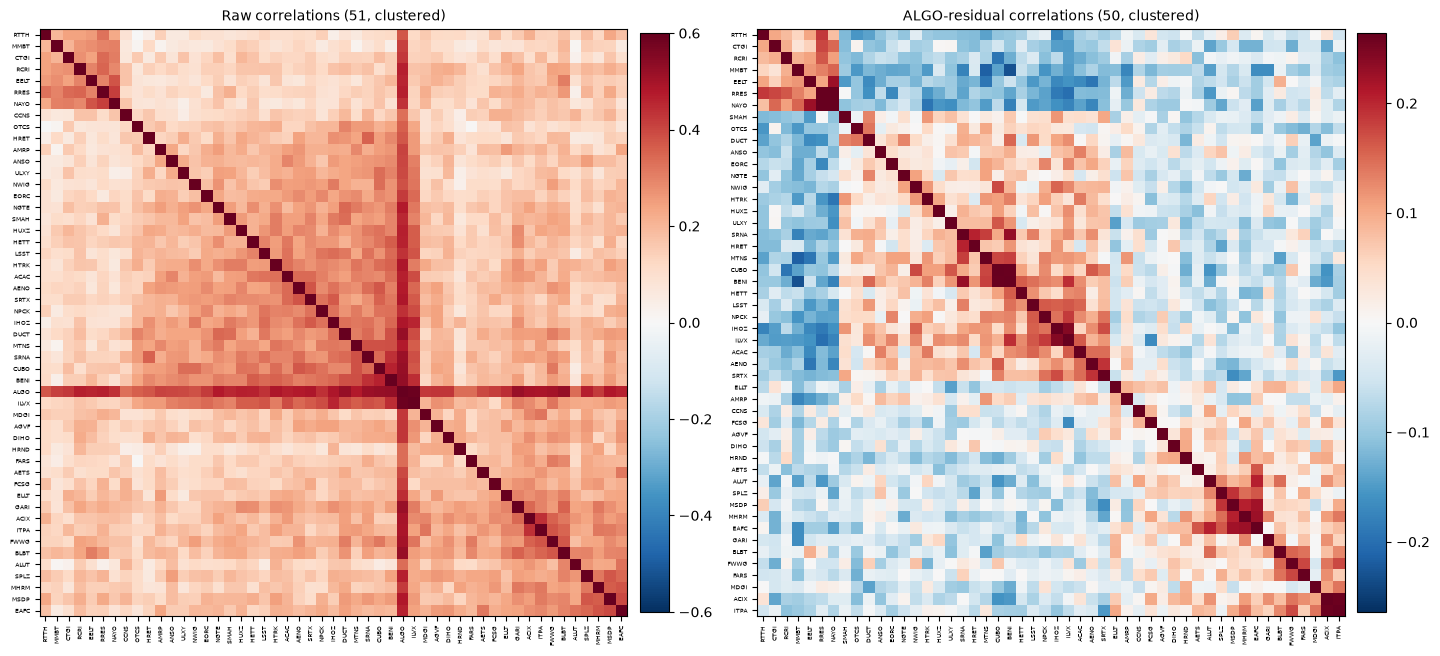

mean off-diag: raw 0.200 | residual -0.010
null benchmark for max |rho| over 1225 pairs at T=499: ~0.17
 RRES - NAYO  resid rho = +0.264
 CUBO - BENI  resid rho = +0.260
 ACIX - ITPA  resid rho = +0.259
 IHOZ - ILVX  resid rho = +0.242
 MMBT - BENI  resid rho = -0.230
 SRNA - BENI  resid rho = +0.229
 NAYO - EELT  resid rho = +0.227
 MHRM - EAFC  resid rho = +0.225
 MSDP - EAFC  resid rho = +0.222
 MMBT - MTNS  resid rho = -0.216


In [10]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

# --- correlation matrices ----------------------------------------------
C_raw = np.corrcoef(rets)                        # all 51, incl. ALGO

X = rets - rets.mean(axis=1, keepdims=True)
a = X[0]                                         # ALGO = the factor
beta = X @ a / (a @ a)                           # per-instrument loading
resid = X - np.outer(beta, a)                    # factor-neutral returns
C_res = np.corrcoef(resid[1:])                   # 50x50, ALGO dropped

iu  = np.triu_indices_from(C_res, k=1)
off = C_res[iu]

def cluster_order(C):
    Z = linkage(squareform(1.0 - C, checks=False), method="average")
    return leaves_list(Z)

o1, o2 = cluster_order(C_raw), cluster_order(C_res)

# --- plot ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.8))
panels = [
    (C_raw[np.ix_(o1, o1)], tickers[o1],     "Raw correlations (51, clustered)",           0.6),
    (C_res[np.ix_(o2, o2)], tickers[1:][o2], "ALGO-residual correlations (50, clustered)", max(0.2, np.abs(off).max())),
]
for ax, (M, names, title, vlim) in zip(axes, panels):
    im = ax.imshow(M, cmap="RdBu_r", vmin=-vlim, vmax=vlim, interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=90, fontsize=4.5)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=4.5)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
plt.tight_layout(); plt.show()

# --- numbers to go with the picture -------------------------------------
T = rets.shape[1]
print(f"mean off-diag: raw {C_raw[np.triu_indices_from(C_raw, 1)].mean():.3f} | residual {off.mean():.3f}")
print(f"null benchmark for max |rho| over {off.size} pairs at T={T}: ~{np.sqrt(2*np.log(off.size)/T):.2f}")
for k in np.argsort(-np.abs(off))[:10]:
    i, j = iu[0][k], iu[1][k]
    print(f"{tickers[1:][i]:>5} - {tickers[1:][j]:<5} resid rho = {off[k]:+.3f}")

log-price ADF rejections (5%): 4/51   (~2.6 expected if all unit roots)
  ADF+KPSS agree stationary: 0 []

coint-vs-ALGO rejections  5%: 3/50 (~2.5 exp.) | 1%: 0 (~0.5 exp.)
    NGTE  p = 0.0333
    NAYO  p = 0.0403
    MTNS  p = 0.0412
    BENI  p = 0.0637
    EORC  p = 0.0771

ARCH-LM(5) rejections: 1/51 (~2.6 exp.) | CUSUM-of-squares breaks: 1/51

beta-to-ALGO: corr(H1,H2) = 0.78, mean|dBeta| = 0.15
residual-factor subspace overlap H1 vs H2: 0.82  (1 = same factors, ~0.08 = unrelated)


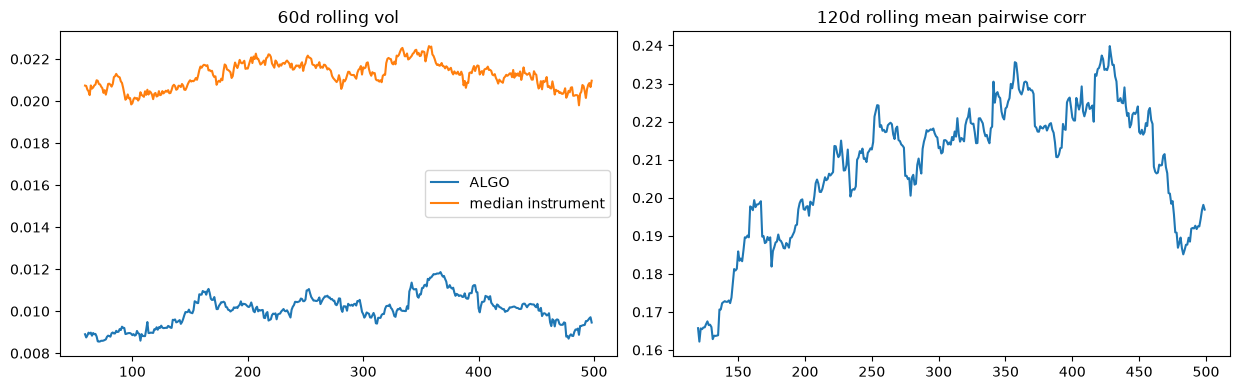

In [11]:
from statsmodels.tsa.stattools import adfuller, kpss, coint
from statsmodels.stats.diagnostic import het_arch

T = rets.shape[1]
logp = np.log(prc)

# ---- 1. unit roots in log-prices (tradable level mean-reversion?) ------
adf_p  = np.array([adfuller(logp[i], regression="c", autolag="AIC")[1] for i in range(nInst)])
kpss_p = np.array([kpss(logp[i], regression="c", nlags="auto")[1]      for i in range(nInst)])
stat_mask = (adf_p < .05) & (kpss_p > .05)            # both tests agree: stationary
print(f"log-price ADF rejections (5%): {(adf_p < .05).sum()}/51   (~2.6 expected if all unit roots)")
print(f"  ADF+KPSS agree stationary: {stat_mask.sum()}", list(tickers[stat_mask]))

# ---- 2. cointegration with ALGO (stationary hedged spreads?) -----------
ci_p = np.array([coint(logp[i], logp[0], trend="c")[1] for i in range(1, nInst)])
print(f"\ncoint-vs-ALGO rejections  5%: {(ci_p < .05).sum()}/50 (~2.5 exp.) | 1%: {(ci_p < .01).sum()} (~0.5 exp.)")
for i in np.argsort(ci_p)[:5]:
    print(f"   {tickers[1:][i]:>5}  p = {ci_p[i]:.4f}")

# ---- 3. variance stationarity ------------------------------------------
arch_p = np.array([het_arch(rets[i] - rets[i].mean(), nlags=5)[1] for i in range(nInst)])
def cusum_sq(x):                                      # Inclan-Tiao, 5% crit ~ 1.358
    c = np.cumsum(x**2); k = np.arange(1, len(x) + 1)
    return np.sqrt(len(x) / 2) * np.abs(c / c[-1] - k / len(x)).max()
it_stat = np.array([cusum_sq(rets[i] - rets[i].mean()) for i in range(nInst)])
print(f"\nARCH-LM(5) rejections: {(arch_p < .05).sum()}/51 (~2.6 exp.) | "
      f"CUSUM-of-squares breaks: {(it_stat > 1.358).sum()}/51")

# ---- 4. one process or two? (H1 vs H2 structure) ------------------------
h = T // 2
def half_stats(R):
    Xh = R - R.mean(1, keepdims=True); a = Xh[0]
    b = Xh @ a / (a @ a); E = Xh - np.outer(b, a)
    w, V = np.linalg.eigh(np.corrcoef(E[1:]))
    return b[1:], V[:, -2:]
b1, V1 = half_stats(rets[:, :h]); b2, V2 = half_stats(rets[:, h:])
print(f"\nbeta-to-ALGO: corr(H1,H2) = {np.corrcoef(b1, b2)[0,1]:.2f}, mean|dBeta| = {np.abs(b1-b2).mean():.2f}")
print(f"residual-factor subspace overlap H1 vs H2: {np.linalg.norm(V1.T @ V2)**2 / 2:.2f}"
      "  (1 = same factors, ~0.08 = unrelated)")

# ---- 5. the pictures behind the tests -----------------------------------
win_v, win_c = 60, 120
roll_vol  = ret_df.rolling(win_v).std()
mean_corr = [np.corrcoef(rets[:, t-win_c:t])[np.triu_indices(nInst, 1)].mean()
             for t in range(win_c, T + 1)]

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
ax[0].plot(roll_vol.iloc[:, 0], label="ALGO", lw=1.5)
ax[0].plot(roll_vol.iloc[:, 1:].median(axis=1), label="median instrument", lw=1.5)
ax[0].set_title(f"{win_v}d rolling vol"); ax[0].legend()
ax[1].plot(range(win_c, T + 1), mean_corr)
ax[1].set_title(f"{win_c}d rolling mean pairwise corr")
plt.tight_layout(); plt.show()

In [12]:
from itertools import combinations

pairs  = list(combinations(range(1, nInst), 2))        # 1225 pairs among the 50
pair_p = np.array([coint(logp[i], logp[j], trend="c")[1] for i, j in pairs])
m = len(pairs)
print(f"pairwise EG cointegration: {m} tests")
print(f"  rejections 5%: {(pair_p < .05).sum()} (~{.05*m:.0f} exp.) | 1%: {(pair_p < .01).sum()} (~{.01*m:.0f} exp.)")
print(f"  min p = {pair_p.min():.5f}   (null-expected min ~{1/(m+1):.5f}; Bonferroni bar {.05/m:.1e})")
for k in np.argsort(pair_p)[:5]:
    i, j = pairs[k]
    print(f"   {tickers[i]:>5} - {tickers[j]:<5} p = {pair_p[k]:.5f}")

pairwise EG cointegration: 1225 tests
  rejections 5%: 84 (~61 exp.) | 1%: 20 (~12 exp.)
  min p = 0.00000   (null-expected min ~0.00082; Bonferroni bar 4.1e-05)
    SMAH - ILVX  p = 0.00000
    AENO - NWIG  p = 0.00000
    EORC - NGTE  p = 0.00001
    HUXZ - ACAC  p = 0.00001
    MHRM - EAFC  p = 0.00007


In [13]:
PAIRS = [("SMAH","ILVX"), ("AENO","NWIG"), ("EORC","NGTE"), ("HUXZ","ACAC"),
         ("MHRM","EAFC"), ("CTGI","EELT"), ("HETT","ULXY")]
tix = {t: k for k, t in enumerate(tickers)}
P, nt = prc, prc.shape[1]
start, LEG, ZCAP, COMM = nt - 250, 10_000, 1.5, 1e-4

def score(mu, sig, param=1.0):
    if mu <= 0 or sig < 1e-10: return mu
    sr = np.sqrt(250) * mu / sig
    return mu * sr**2 / (sr**2 + param**2)

pos, pll, comm_tot = np.zeros(nInst, int), [], 0.0
for t in range(start - 1, nt - 1):
    hist = np.log(P[:, :t + 1])
    tgt = np.zeros(nInst)
    for a, b in PAIRS:
        i, j = tix[a], tix[b]
        bb, cc = np.polyfit(hist[j], hist[i], 1)
        s = hist[i] - bb * hist[j] - cc
        z = (s[-1] - s.mean()) / s.std()
        w = -np.clip(z / ZCAP, -1, 1)                 # proportional, saturating
        tgt[i] += w * LEG / P[i, t]
        tgt[j] -= w * bb * LEG / P[j, t]
    lims = (10_000 / P[:, t]).astype(int)
    new  = np.clip(tgt, -lims, lims).astype(int)
    comm = np.abs(new - pos) @ P[:, t] * COMM
    pll.append(new @ (P[:, t + 1] - P[:, t]) - comm)
    comm_tot += comm; pos = new

pll = np.array(pll); mu, sig = pll.mean(), pll.std()
print(mu, sig, np.sqrt(250) * mu / sig, score(mu, sig), comm_tot)

200.527545856 465.915818964178 6.805132522851448 196.2889436128091 696.4135360000002
